In [22]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers, models, regularizers
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [23]:
digits = load_digits()

print(digits.data.shape)
print(digits.images.shape)
print(digits.target.shape)
print(digits.target_names)

(1797, 64)
(1797, 8, 8)
(1797,)
[0 1 2 3 4 5 6 7 8 9]


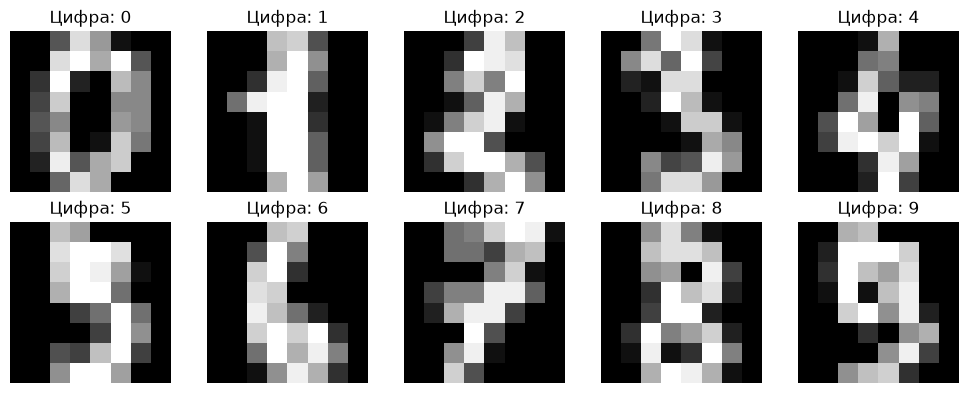

In [24]:
fig, axes = plt.subplots(2,5,figsize=(10,4))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Цифра: {digits.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
values, counts = np.unique(digits.target, return_counts=True)

for digit, count in zip(values, counts):
    print(digit, count)

0 178
1 182
2 177
3 183
4 181
5 182
6 181
7 179
8 174
9 180


In [26]:
X = digits.data / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train_cnn = X_train.reshape(-1, 8, 8, 1)
X_test_cnn = X_test.reshape(-1, 8, 8, 1)

In [27]:
model_mlp = models.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(
        64, 
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001),
    ),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

model_mlp.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,810 (18.79 KB)

 Trainable params: 4,810 (18.79 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model_mlp.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

In [29]:
early_stop_mlp = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

history_mlp = model_mlp.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=150,
    batch_size=32,
    callbacks=[early_stop_mlp]
)

Epoch 1/150


41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.2652 - sparse_categorical_accuracy: 0.1562 - val_loss: 2.0812 - val_sparse_categorical_accuracy: 0.3403
Epoch 2/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.9612 - sparse_categorical_accuracy: 0.4756 - val_loss: 1.8147 - val_sparse_categorical_accuracy: 0.7292
Epoch 3/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.7082 - sparse_categorical_accuracy: 0.6473 - val_loss: 1.5709 - val_sparse_categorical_accuracy: 0.8194
Epoch 4/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.4684 - sparse_categorical_accuracy: 0.7355 - val_loss: 1.3511 - val_sparse_categorical_accuracy: 0.8681
Epoch 5/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2862 - sparse_categorical_accuracy: 0.7664 - val_loss: 1.1624 - val_sparse_categorical_accuracy: 0.8819
Epoch 6/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1176 - sparse_categorical_accuracy: 0.7943 - val_loss: 1.0133 - val_sparse_categorical_accuracy: 0.8681
Epoch 7/150
41/41 ━━━━

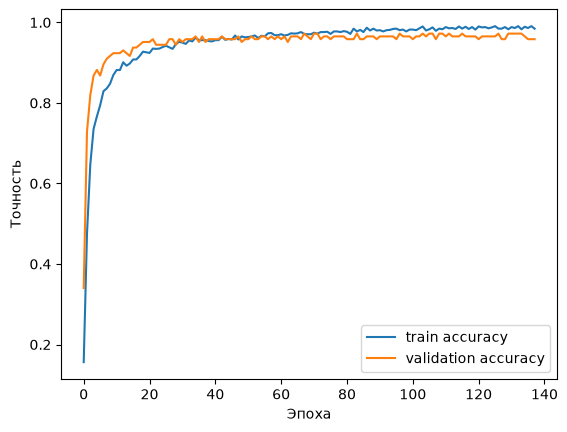

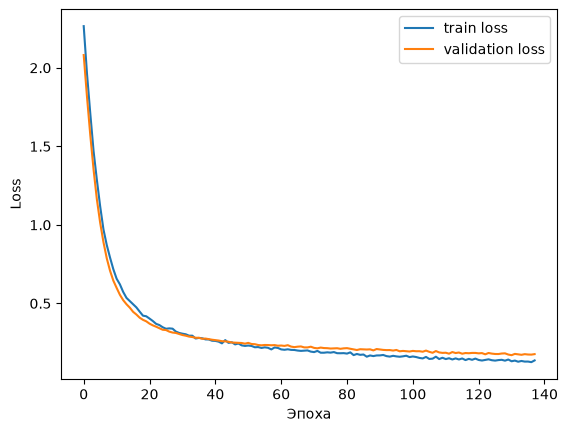

In [30]:
plt.plot(history_mlp.history['sparse_categorical_accuracy'], label='train accuracy')
plt.plot(history_mlp.history['val_sparse_categorical_accuracy'], label='validation accuracy')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.show()

plt.plot(history_mlp.history['loss'], label='train loss')
plt.plot(history_mlp.history['val_loss'], label='validation loss')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [31]:
loss, accuracy = model_mlp.evaluate(X_test, y_test)
print(f"Точность на тесте: {accuracy:.3f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1523 - sparse_categorical_accuracy: 0.9750 
Точность на тесте: 0.975


In [32]:
probs = model_mlp.predict(X_test[:10])
predictions = np.argmax(probs, axis=1)
print("Предсказания:", predictions)
print("Правильные:  ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Предсказания: [5 2 8 1 7 2 6 2 6 5]
Правильные:   [5 2 8 1 7 2 6 2 6 5]


In [33]:
y_pred = np.argmax(model_mlp.predict(X_test), axis=1)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 34  0  0  0  0  0  0  2  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 36  0  1  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  3  0  0  0  0  0  0 32  0]
 [ 0  0  0  0  0  0  0  1  0 35]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      0.94      0.93        36
           2       1.00      1.00      1.00        35
           3       1.00      0.97      0.99        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.91      0.91      0.91        35
           9       1.00      0.97      0.99        36

    accuracy                     

In [34]:
model_cnn = models.Sequential([
    layers.Input(shape=(8, 8, 1)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Flatten(),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

model_cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,066 (332.29 KB)

 Trainable params: 85,066 (332.29 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model_cnn.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

In [36]:
early_stop_cnn = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

history_cnn = model_cnn.fit(
    X_train_cnn, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_cnn]
)

Epoch 1/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 2.3243 - sparse_categorical_accuracy: 0.2993 - val_loss: 2.1811 - val_sparse_categorical_accuracy: 0.6250
Epoch 2/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.0118 - sparse_categorical_accuracy: 0.5654 - val_loss: 1.7387 - val_sparse_categorical_accuracy: 0.7014
Epoch 3/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.5148 - sparse_categorical_accuracy: 0.6790 - val_loss: 1.1733 - val_sparse_categorical_accuracy: 0.8264
Epoch 4/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.0336 - sparse_categorical_accuracy: 0.7711 - val_loss: 0.7827 - val_sparse_categorical_accuracy: 0.8403
Epoch 5/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7726 - sparse_categorical_accuracy: 0.8144 - val_loss: 0.5786 - val_sparse_categorical_accuracy: 0.9097
Epoch 6/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6234 - sparse_categorical_accuracy: 0.8538 - val_loss: 0.4771 - val_sparse_categorical_accuracy: 0.8819
Epoch 7/1

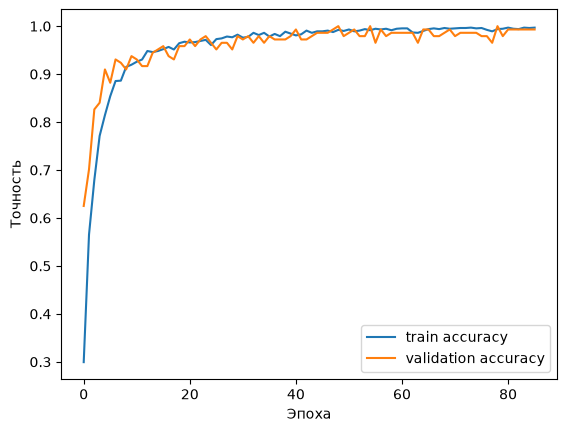

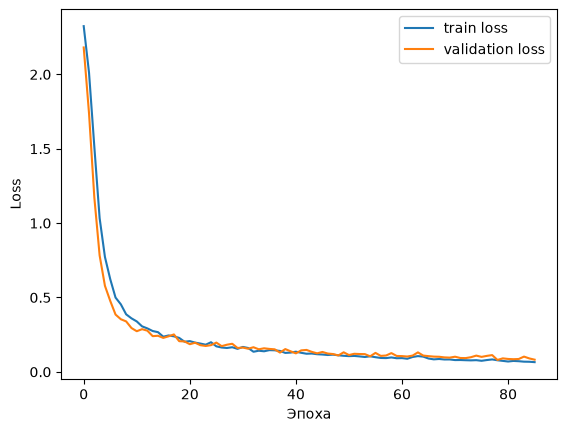

In [37]:
plt.plot(history_cnn.history['sparse_categorical_accuracy'], label='train accuracy')
plt.plot(history_cnn.history['val_sparse_categorical_accuracy'], label='validation accuracy')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.show()

plt.plot(history_cnn.history['loss'], label='train loss')
plt.plot(history_cnn.history['val_loss'], label='validation loss')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [38]:
loss, accuracy = model_cnn.evaluate(X_test_cnn, y_test)
print(f"Точность на тесте: {accuracy:.3f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1059 - sparse_categorical_accuracy: 0.9806 
Точность на тесте: 0.981


In [39]:
probs = model_cnn.predict(X_test_cnn[:10])
predictions = np.argmax(probs, axis=1)
print("Предсказания:", predictions)
print("Правильные:  ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Предсказания: [5 2 8 1 7 2 6 2 6 5]
Правильные:   [5 2 8 1 7 2 6 2 6 5]


In [40]:
y_pred = np.argmax(model_cnn.predict(X_test_cnn), axis=1)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 35  0  0  0  0  0  0  1  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  2  0  0  0  0  0  1 32  0]
 [ 0  0  0  0  0  0  0  1  0 35]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       0.95      1.00      0.97        36
           8       0.94      0.91      0.93        35
           9       1.00      0.97      0.99        36

    accuracy                     

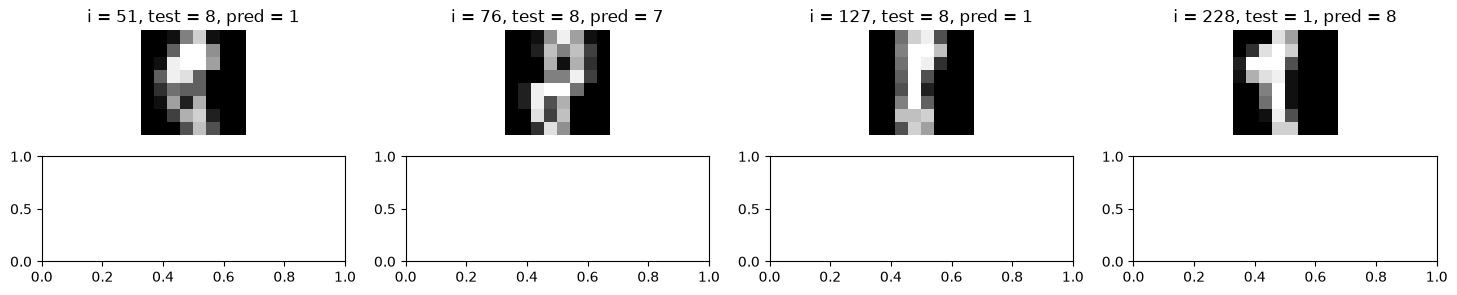

In [41]:
mask = (
    ((y_test == 1) & (y_pred != 1)) |
    ((y_test == 8) & (y_pred != 8))
)

indices = np.flatnonzero(mask)

size = len(indices)

fig, axes = plt.subplots(size // 4 + 1, 4, figsize=(18, 3 * size // 4))

for i, ax in zip(indices, axes.flat):
    ax.imshow(X_test_cnn[i, :, :, 0], cmap="gray")
    ax.set_title(f"i = {i}, test = {y_test[i]}, pred = {y_pred[i]}")
    ax.axis("off")